In [1]:
import pickle
import pandas as pd
import ast
import re
from deep_translator import GoogleTranslator

from config import RESSERENO_ROOT
from jaccard_similarity_bfmn import results_jaccard_similarities, plot_comparison

In [2]:
pd.set_option('display.max_colwidth', None)

In [2]:
path_rassereno_analysis = RESSERENO_ROOT / "out" / "analysis"

# Latex Table

## Cue words dicts and correspondence

In [ ]:
cue_words_df = pd.read_csv(f'{RESSERENO_ROOT}/out/formatting/cue_words_summary.csv')
cue_words_df['Set'] = ['1', '2' , '3', '4', '5']

# Collect all words in each row (excluding 'Set'), split by comma, and strip whitespace
cue_words_df['words'] = cue_words_df.drop(columns='Set').apply(
    lambda row: [word.strip() for cell in row.dropna() for word in str(cell).split(',')],
    axis=1
)

cue_words_df = cue_words_df[['Set', 'words']]
map_words = {'Examination': 'Exam', "Well being" : 'Wellbeing'}

# Replace mapped words in cue_words for each row
cue_words_df['words'] = cue_words_df['words'].apply(lambda word_list: sorted([map_words.get(word, word) for word in word_list]))

In [145]:
set_words_sample = {
    ('1'): ['Experts', 'H-S South'], 
    ('5'): ['H-Anx H-S', 'L-Anx H-S', 'Physics'],
    ('2', '3', '4', '5'): ['H-Anx Psy', 'L-Anx Psy', 'GPT H-Anx Psy', 'GPT L-Anx Psy', 'GPT Physics', 'GPT H-Anx H-S', 'GPT L-Anx H-S'],
}
sample_to_sets = {
    sample: list(sets_words)
    for sets_words, samples in set_words_sample.items()
    for sample in samples
}

## Functions

In [146]:
def translate_and_italicize_hubs(df, col="Hubs", cue_words=None, source="it", target="en", set_words_sample=set_words_sample):

    if cue_words is None:
        cue_words = []

    new_df = df.copy()

    # Ensure lists are lists, not stringified lists
    new_df[col] = new_df[col].apply(ast.literal_eval)

    # Collect unique node words (before parentheses)
    unique_nodes = list({
        re.search(r'^[^()]+', el).group(0).strip().capitalize()
        for lst in new_df[col] for el in lst
    })

    # Join for one-shot translation
    joined = "\n".join(unique_nodes)

    # Translate in one API call
    translated_blob = GoogleTranslator(source=source, target=target).translate(joined)
    translated_list = translated_blob.split("\n")

    # Map original capitalized node → translated node
    translation_map = dict(zip(unique_nodes, translated_list))

    # Build final processed column
    processed_col = []
    n_hubs_records = []

    for idx, lst in enumerate(new_df[col]):
        processed_list = []

        for el in lst:
            node = re.search(r'^[^()]+', el).group(0).strip()
            degree = re.search(r'\(\d+\)', el).group(0)

            translated_node = translation_map[node.capitalize()]
            
            set_for_sample = sample_to_sets.get(new_df.loc[idx, "Sample"], [])
            cue_words_for_this_sample = (cue_words_df.loc[cue_words_df["Set"].isin(set_for_sample), "words"].explode().tolist())

            if translated_node in cue_words_for_this_sample:
                formatted = f"\\textit{{{translated_node}}} {degree}"
            else:
                formatted = f"{translated_node} {degree}"

            processed_list.append(formatted)

            # Join as clean string
        processed_col.append(", ".join(processed_list))

        # Count hubs
        n_hubs_records.append({
            "Sample": new_df.loc[idx, "Sample"],
            "N Hubs": len(lst)
        })

    new_df[col] = processed_col
    n_hubs_df = pd.DataFrame(n_hubs_records)

    return new_df, n_hubs_df

In [ ]:
def mapping_cols_df(features_df):
    keyword_map = {
        "ansia": "anxiety",
        "benessere": "wellbeing",
        "computer": "computer science", 
        "esame": "exam",
        "fisica": "physics",
        "scuola": "school",
        "informatica": "computer science",
        "insegnante": "teacher",
        "matematica": "mathematics",
        "math": "mathematics",
        "professore": "professor",
        "scienza": "science",
        "scuola": "school",
        "scienziato": "scientist (male)",
        "scienziata": "scientist (female)",
        "statistica": "statistics",
        "studente": "student",
        "universita": "university",
        "ricerca": "research",
        "voto": "grade",
        "scientist": "scientist (m/f)"
    }
    sample_map = {
        "experts_2019": "Experts",
        "liceo_2019": "H-S South",
        "liceo_2025/high_anxiety": "H-Anx H-S",
        "liceo_2025/low_anxiety": "L-Anx H-S",
        "gpt_oss_high_school/high_anxiety": "GPT H-Anx H-S",
        "gpt_oss_high_school/low_anxiety": "GPT L-Anx H-S",
        "physics_students_2025": "Physics",
        "gpt_oss_physics": "GPT Physics",
        "psychology_students_unfiltered/high_anxiety": "H-Anx Psy",
        "psychology_students_unfiltered/low_anxiety": "L-Anx Psy",
        "gpt_oss_psychology/high_anxiety": "GPT H-Anx Psy",
        "gpt_oss_psychology/low_anxiety": "GPT L-Anx Psy",
    }

    if "keyword" in features_df.columns:  
        features_df["keyword"] = features_df["keyword"].map(keyword_map).fillna(features_df["keyword"])

    features_df["Sample"] = features_df["Sample"].map(sample_map).fillna(features_df["Sample"])

    features_df_cleaned, n_hubs_df = translate_and_italicize_hubs(features_df, cue_words=cue_words_df)
    
    return features_df_cleaned, n_hubs_df

## Feature keyword fmns

In [127]:
all_keyword_fmns_features = pd.read_csv(f'{path_rassereno_analysis}/features_keyword_fmns.csv')

In [169]:
keyword_fmns_features_cleaned, hubs_df = mapping_cols_df(all_keyword_fmns_features)

In [ ]:
keyword_fmns_features_cleaned = keyword_fmns_features_cleaned.rename(columns={'Hubs': 'Hubs (top 5\\% of degree distribution)'})

,Sample,keyword,$N_v$,$N_e$,$C_i$,$l_G$,Hubs (top 5\% of degree distribution)
0,Experts,mathematics,48,107,0.055504,1.905142,"\textit{Mathematics} (47), \textit{Physics} (11), \textit{Science} (10)"
1,Experts,statistics,26,38,0.043333,1.883077,"\textit{Statistics} (25), \textit{Mathematics} (5), \textit{Number} (5)"
2,Experts,physics,55,108,0.037736,1.927273,"\textit{Physics} (54), \textit{Science} (15), \textit{Mathematics} (11)"
3,Experts,science,66,156,0.043750,1.927273,"\textit{Science} (65), \textit{Physics} (15), System (12), \textit{Complex} (11)"
4,Experts,computer science,27,40,0.043077,1.886040,"Computers (26), \textit{Science} (7)"
...,...,...,...,...,...,...,...
172,GPT L-Anx Psy,scientist (male),71,105,0.014493,1.957746,"\textit{Scientist} (70), \textit{Science} (22), \textit{University} (9), \textit{Curiosity} (6)"
173,GPT L-Anx Psy,school,4,3,0.000000,1.500000,\textit{School} (3)
174,GPT L-Anx Psy,university,53,75,0.017345,1.945573,"\textit{University} (52), \textit{Scientist} (9), \textit{Science} (7)"
175,GPT L-Anx Psy,anxiety,36,55,0.033613,1.912698,"\textit{Anxiety} (35), Tests (6), \textit{Exam} (6), \textit{Stress} (6)"


In [ ]:
keywords = ['mathematics', 'statistics', 'computer science', 'physics', 'science', 'research', 'exam', 'grade', 'professor', 'teacher', 'scientist', 'scientist (male)', 'scientist (female)', 'school', 'university', 'anxiety', 'wellbeing']

In [180]:
for keyword in keywords:
    df_keyword = keyword_fmns_features_cleaned[keyword_fmns_features_cleaned['keyword'] == keyword].drop(columns=['keyword']).to_latex(
                                                                                       index=False,
                                                                                       escape=False,
                                                                                       float_format="%.2f", 
                                                                                       position="!hbpt", 
                                                                                       column_format ="lccccp{9cm}",
                                                                                       caption=f"Network features for the semantic frame of \\textit{{\\textbf{{{keyword.capitalize()}}}}}. For each hub, its degree is reported in parentheses. The italicised hubs are part of the cue words.",
                                                                                       label=f"tab:network_features_{keyword}",
                                                                                       )
    df_latex = df_keyword.replace(r"\begin{table}[!hbpt]", f"\\begin{{table}}[!hbpt]\n\\footnotesize\n\\centering")
    
    with open(f'{path_rassereno_analysis}/features_keyword_fmns_latex.txt', "a") as f:
        f.write(f"{df_latex}\n")

## Feature total fmns

In [159]:
all_tot_fmns_features = pd.read_csv(f'{path_rassereno_analysis}/features_tot_fmns.csv')

In [172]:
tot_fmns_features_cleaned, hubs = mapping_cols_df(all_tot_fmns_features)

In [173]:
tot_fmns_features_cleaned = tot_fmns_features_cleaned.rename(columns={'Hubs': 'Hubs (top 1\\% of degree distribution)'})

In [181]:
tot_features_latex = tot_fmns_features_cleaned.to_latex(
    index=False,
    escape=False,
    float_format="%.2f", 
    position="!hbpt", 
    column_format ="lccccp{9.5cm}",
    caption="Network features for the total semantic frame of each sample. For each hub, its degree is reported in parentheses. The italicised hubs are part of the cue words.",
    label="tab:network_features_total",
    )
tot_features_latex = tot_features_latex.replace(r"\begin{table}[!hbpt]", f"\\begin{{table}}[!hbpt]\n\\footnotesize\n\\centering")

with open(f'{path_rassereno_analysis}/features_tot_fmns_latex.txt', "w") as f:
    f.write(f"{tot_features_latex}\n")

## Keywords

In [235]:
keywords_rassereno_eng = ['mathematics', 'statistics', 'physics', 'science', 'computer', 'research', 'exam','grade', 'professor', 'teacher', 'scientist', 'school', 'university', 'anxiety', 'wellbeing']

cap_keywords = [w.capitalize().replace("'", "") for w in keywords_rassereno_eng]

dict_words = {'Experiment 1' : [cap_keywords[:6]], 
              'Experiment 2' : [cap_keywords[6:13]], 
              'Experiment 3' : [cap_keywords[13:]]}
df_words = pd.DataFrame.from_dict(dict_words)
df_words.to_latex()

"\\begin{tabular}{llll}\n\\toprule\n & Experiment 1 & Experiment 2 & Experiment 3 \\\\\n\\midrule\n0 & ['Mathematics', 'Statistics', 'Physics', 'Science', 'Computer', 'Research'] & ['Exam', 'Grade', 'Professor', 'Teacher', 'Scientist', 'School', 'University'] & ['Anxiety', 'Wellbeing'] \\\\\n\\bottomrule\n\\end{tabular}\n"

# Jaccard Similarity

In [5]:
# features_df = pd.read_json('/Users/emma/projects/cognoscolab/rassereno/notebooks/all_fmnts.json')
with open(f'{path_rassereno_analysis}/all_bfmns.pkl', 'rb') as f:
    features = pickle.load(f)

## Psychology students

In [9]:
low_anx_psychology = results_jaccard_similarities(features, 'gpt_oss_psychology_low_anx', 'psychology_low_anx')

gpt_oss_psychology_low_anx:
matematica - ansia: 0.0136986301369863
matematica - esame: 0.03278688524590164
esame - ansia: 0.03508771929824561

psychology_low_anx:
matematica - ansia: 0.03731343283582089
matematica - esame: 0.07079646017699115
esame - ansia: 0.15315315315315314


In [10]:
high_anx_psychology = results_jaccard_similarities(features, 'gpt_oss_psychology_high_anx', 'psychology_high_anx')

gpt_oss_psychology_high_anx:
matematica - ansia: 0.014925373134328358
matematica - esame: 0.03571428571428571
esame - ansia: 0.038461538461538464

psychology_high_anx:
matematica - ansia: 0.12837837837837837
matematica - esame: 0.10810810810810811
esame - ansia: 0.13385826771653545


## High school students 2025

In [11]:
low_anx_high_school = results_jaccard_similarities(features, 'gpt_oss_high_school_low_anx', 'high_school_low_anx')

gpt_oss_high_school_low_anx:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

high_school_low_anx:
matematica - ansia: 0.04
matematica - esame: 0.054945054945054944
esame - ansia: 0.08860759493670886


In [12]:
high_anx_high_school = results_jaccard_similarities(features, 'gpt_oss_high_school_high_anx', 'high_school_high_anx')

gpt_oss_high_school_high_anx:
matematica - ansia: 0.0
matematica - esame: 0.03225806451612903
esame - ansia: 0.0

high_school_high_anx:
matematica - ansia: 0.0546875
matematica - esame: 0.07407407407407407
esame - ansia: 0.07920792079207921


## Fisica

In [13]:
physics = results_jaccard_similarities(features, 'gpt_oss_physics', 'physics')

gpt_oss_physics:
matematica - ansia: 0.0
matematica - esame: 0.0
esame - ansia: 0.0

physics:
matematica - ansia: 0.0196078431372549
matematica - esame: 0.029411764705882353
esame - ansia: 0.05128205128205128


## Plots

In [18]:
all_results = {**low_anx_psychology,
               **high_anx_psychology,
               **low_anx_high_school,
               **high_anx_high_school,
               **physics}

In [15]:
rows = []
for k, (v1, v2, v3) in all_results.items():
    source = 'GPT-oss' if 'gpt' in k else 'Humans'
    group = k.replace('gpt_oss_', '').replace('_', ' ').title()
    rows.append({'group': group, 'source': source, 'comparison_1': v1, 'comparison_2': v2, 'comparison_3':v3})

similarities = pd.DataFrame(rows).sort_values('group')
for col in ['comparison_1', 'comparison_2', 'comparison_3']:
    for idx in range(len(similarities[col])):
        if similarities.loc[idx, col] == 0:
            similarities.loc[idx, col] = 0.001

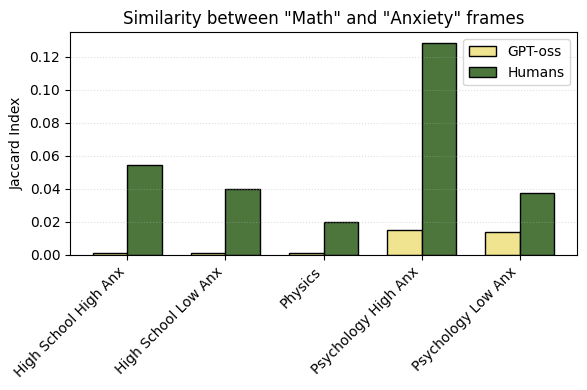

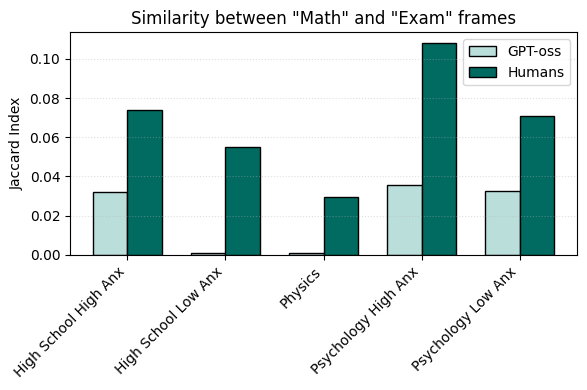

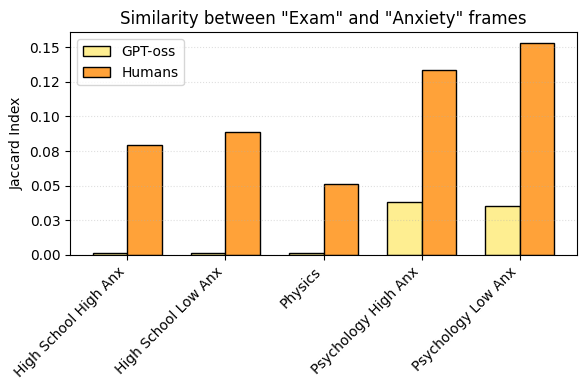

In [17]:
plot_comparison(similarities, 'comparison_1', 'Similarity between "Math" and "Anxiety" frames', '#F0E491', '#4C763B', path_rassereno_analysis)
plot_comparison(similarities, 'comparison_2', 'Similarity between "Math" and "Exam" frames','#BADFDB', '#016B61', path_rassereno_analysis)
plot_comparison(similarities, 'comparison_3', 'Similarity between "Exam" and "Anxiety" frames','#FEEE91', '#FFA239', path_rassereno_analysis)